# Titanic Survival Prediction: SVM vs Random Forest vs AdaBoost

## 1. Aim and Imports

**Aim:** Implement and compare three classifiers — **Support Vector Machine (SVM)**, **Random Forest** and **AdaBoost** — for predicting Titanic passenger survival. The experiment performs:

- 5-fold Stratified Cross-Validation
- Hyperparameter tuning using Grid Search (`GridSearchCV`)
- Evaluation and comparison of model performance **before and after optimization**

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

sns.set_style('whitegrid')
RANDOM_STATE = 42

## 2. Dataset Loading and Exploration

Upload `train.csv` (Titanic training set) when prompted. If the file already exists in the Colab working directory (or you have mounted Drive and set the path), it is loaded directly.

In [ ]:
import os
CSV_PATH = '/content/train (1).csv'   # change this if your file has a different name/path

if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        CSV_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError('Place the Titanic CSV in the working directory and set CSV_PATH.')

df = pd.read_csv(CSV_PATH)
print('Loaded:', CSV_PATH)
df.head()

Loaded: /content/train (1).csv


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print('Shape:', df.shape)
print('\nColumns:', df.columns.tolist())
print('\nMissing values:')
print(df.isnull().sum()[df.isnull().sum() > 0])

Shape: (891, 12)

Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Missing values:
Age         177
Cabin       687
Embarked      2
dtype: int64


Survival class distribution (counts):
Survived
0    549
1    342
Name: count, dtype: int64

Survival class distribution (%):
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


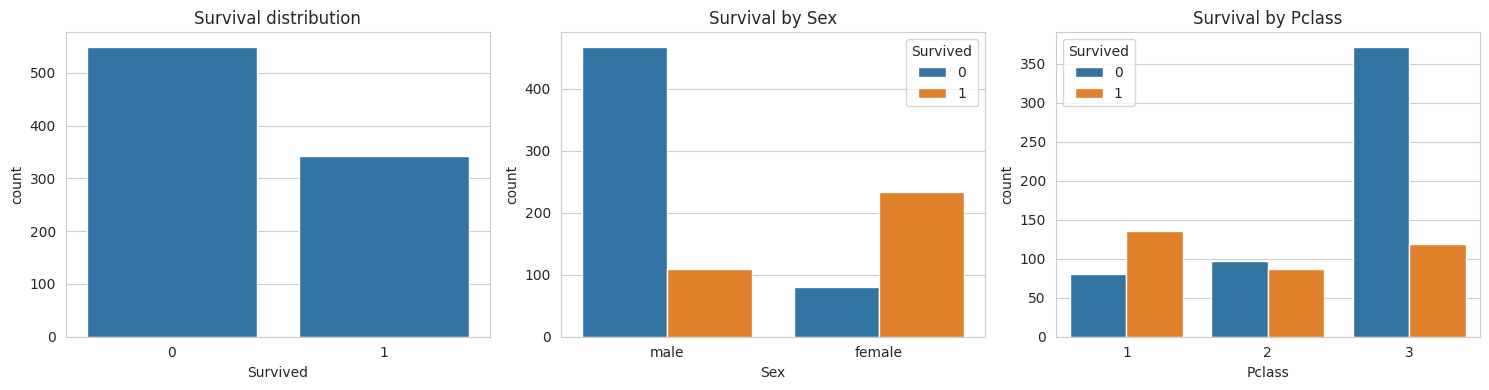

In [ ]:
print('Survival class distribution (counts):')
print(df['Survived'].value_counts())
print('\nSurvival class distribution (%):')
print((df['Survived'].value_counts(normalize=True) * 100).round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='Survived', data=df, ax=ax[0]); ax[0].set_title('Survival distribution')
sns.countplot(x='Sex', hue='Survived', data=df, ax=ax[1]); ax[1].set_title('Survival by Sex')
sns.countplot(x='Pclass', hue='Survived', data=df, ax=ax[2]); ax[2].set_title('Survival by Pclass')
plt.tight_layout(); plt.show()

In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


In [ ]:
num_cols_all = df.select_dtypes(include=np.number).columns.tolist()
cat_cols_all = df.select_dtypes(include='object').columns.tolist()
print('Numerical features :', num_cols_all)
print('Categorical features:', cat_cols_all)

Numerical features : ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical features: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


## 3. Preprocessing and Data Splitting

- **Target:** `Survived`
- **Features:** `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`
- Missing values: median imputation (numeric), most-frequent imputation (categorical)
- Categorical variables: one-hot encoding
- Numerical variables: standard scaling (needed for SVM; harmless for tree models)

All preprocessing is wrapped in a `Pipeline` together with the classifier, so imputation/scaling are fitted **only on training folds** — this prevents data leakage during cross-validation and grid search.

In [ ]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = df[features]
y = df['Survived']

num_features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
cat_features = ['Sex', 'Embarked']

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_features),
    ('cat', cat_pipe, cat_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print('Train size:', X_train.shape, '| Test size:', X_test.shape)
print('Train survival rate:', round(y_train.mean(), 4), '| Test survival rate:', round(y_test.mean(), 4))

Train size: (712, 7) | Test size: (179, 7)
Train survival rate: 0.3834 | Test survival rate: 0.3855


## 4. Baseline Model Training and Evaluation

Each classifier is trained with default (or predefined) baseline parameters.

In [ ]:
def make_pipe(clf):
    return Pipeline([('prep', preprocessor), ('clf', clf)])

baseline_models = {
    'SVM': make_pipe(SVC(random_state=RANDOM_STATE)),
    'Random Forest': make_pipe(RandomForestClassifier(random_state=RANDOM_STATE)),
    'AdaBoost': make_pipe(AdaBoostClassifier(random_state=RANDOM_STATE)),
}

def evaluate(model, X_te, y_te):
    pred = model.predict(X_te)
    return {
        'Accuracy': accuracy_score(y_te, pred),
        'Precision': precision_score(y_te, pred),
        'Recall': recall_score(y_te, pred),
        'F1-score': f1_score(y_te, pred),
    }

baseline_results = {}
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    baseline_results[name] = evaluate(model, X_test, y_test)

baseline_df = pd.DataFrame(baseline_results).T.round(4)
print('Baseline performance on the test set')
baseline_df

Baseline performance on the test set


,Accuracy,Precision,Recall,F1-score
SVM,0.8156,0.8214,0.6667,0.7360
Random Forest,0.8156,0.8000,0.6957,0.7442
AdaBoost,0.7821,0.7500,0.6522,0.6977


## 5. Cross-Validation

5-fold Stratified Cross-Validation on the training set to compare the baseline models.

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
cv_scores_store = {}
for name, model in baseline_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='accuracy')
    cv_scores_store[name] = scores
    cv_rows.append({'Model': name, 'Fold scores': np.round(scores, 4),
                    'Mean CV Accuracy': scores.mean(), 'Std': scores.std()})

cv_df = pd.DataFrame(cv_rows).set_index('Model')
cv_df[['Mean CV Accuracy', 'Std']] = cv_df[['Mean CV Accuracy', 'Std']].round(4)
cv_df

,Fold scores,Mean CV Accuracy,Std
Model,,,
SVM,"[0.8392, 0.8112, 0.8592, 0.7887, 0.8099]",0.8216,0.0247
Random Forest,"[0.8182, 0.7972, 0.8239, 0.7817, 0.8099]",0.8062,0.0152
AdaBoost,"[0.8182, 0.7692, 0.8169, 0.8028, 0.831]",0.8076,0.0212


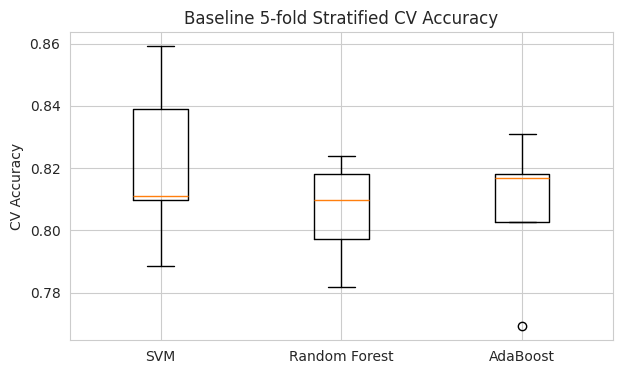

In [ ]:
plt.figure(figsize=(7, 4))
plt.boxplot(list(cv_scores_store.values()), labels=list(cv_scores_store.keys()))
plt.ylabel('CV Accuracy'); plt.title('Baseline 5-fold Stratified CV Accuracy')
plt.show()

## 6. Hyperparameter Tuning Using Grid Search

`GridSearchCV` with 5-fold Stratified CV, optimizing accuracy. Parameter names carry the `clf__` prefix because the classifier sits inside a pipeline.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

param_grids = {
    'SVM': {
        'clf__C': [0.1, 1, 10, 100],
        'clf__gamma': ['scale', 0.01, 0.1, 1],
        'clf__kernel': ['rbf', 'linear'],
    },
    'Random Forest': {
        'clf__n_estimators': [100, 200, 300],
        'clf__max_depth': [None, 5, 10, 15],
        'clf__min_samples_split': [2, 5, 10],
        'clf__min_samples_leaf': [1, 2, 4],
    },
    'AdaBoost': {
        'clf__n_estimators': [50, 100, 200, 300],
        'clf__learning_rate': [0.01, 0.1, 0.5, 1.0],
        'clf__estimator': [DecisionTreeClassifier(max_depth=1),
                           DecisionTreeClassifier(max_depth=2),
                           DecisionTreeClassifier(max_depth=3)],
    },
}

In [ ]:
best_models = {}
grid_rows = []

for name, model in baseline_models.items():
    gs = GridSearchCV(model, param_grids[name], cv=skf, scoring='accuracy', n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    best_params = {k.replace('clf__', ''): (v if not hasattr(v, 'max_depth') else f'DecisionTree(max_depth={v.max_depth})')
                   for k, v in gs.best_params_.items()}
    grid_rows.append({'Model': name, 'Best CV Accuracy': round(gs.best_score_, 4), 'Best Parameters': best_params})
    print(f'{name}\n  Best params : {best_params}\n  Best CV acc : {gs.best_score_:.4f}\n')

pd.DataFrame(grid_rows).set_index('Model')

SVM
  Best params : {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
  Best CV acc : 0.8287

Random Forest
  Best params : {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
  Best CV acc : 0.8259

AdaBoost
  Best params : {'estimator': 'DecisionTree(max_depth=2)', 'learning_rate': 0.5, 'n_estimators': 200}
  Best CV acc : 0.8174



,Best CV Accuracy,Best Parameters
Model,,
SVM,0.8287,"{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}"
Random Forest,0.8259,"{'max_depth': 10, 'min_samples_leaf': 1, 'min_..."
AdaBoost,0.8174,"{'estimator': 'DecisionTree(max_depth=2)', 'le..."


## 7. Optimized Model Evaluation and Comparison

The tuned models (refit on the full training set) are evaluated on the **same held-out test set**.

In [ ]:
opt_results = {name: evaluate(m, X_test, y_test) for name, m in best_models.items()}
optimized_df = pd.DataFrame(opt_results).T.round(4)
print('Optimized performance on the test set')
optimized_df

Optimized performance on the test set


,Accuracy,Precision,Recall,F1-score
SVM,0.8045,0.8148,0.6377,0.7154
Random Forest,0.8101,0.8182,0.6522,0.7258
AdaBoost,0.7933,0.7500,0.6957,0.7218


In [ ]:
comparison = pd.concat(
    {'Baseline': baseline_df, 'Optimized': optimized_df}, axis=1
).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
rows = []
for name in baseline_df.index:
    for stage, d in [('Baseline', baseline_df), ('Optimized', optimized_df)]:
        rows.append({'Model': name, 'Stage': stage, **d.loc[name].to_dict()})
comp_df = pd.DataFrame(rows).set_index(['Model', 'Stage'])
comp_df

Accuracy  Precision  Recall  F1-score
Model         Stage                                           
SVM           Baseline     0.8156     0.8214  0.6667    0.7360
              Optimized    0.8045     0.8148  0.6377    0.7154
Random Forest Baseline     0.8156     0.8000  0.6957    0.7442
              Optimized    0.8101     0.8182  0.6522    0.7258
AdaBoost      Baseline     0.7821     0.7500  0.6522    0.6977
              Optimized    0.7933     0.7500  0.6957    0.7218

## 8. Results and Conclusion

In [ ]:
summary = pd.DataFrame({
    'Baseline Accuracy': baseline_df['Accuracy'],
    'Optimized Accuracy': optimized_df['Accuracy'],
    'Baseline F1': baseline_df['F1-score'],
    'Optimized F1': optimized_df['F1-score'],
    'Baseline CV Acc (mean)': [cv_scores_store[m].mean().round(4) for m in baseline_df.index],
})
display(summary)

best_name = optimized_df['Accuracy'].idxmax()
print(f"Best optimized model by test accuracy: {best_name} ({optimized_df.loc[best_name, 'Accuracy']:.4f})")
print(f"Best optimized model by test F1-score : {optimized_df['F1-score'].idxmax()} ({optimized_df['F1-score'].max():.4f})")

,Baseline Accuracy,Optimized Accuracy,Baseline F1,Optimized F1,Baseline CV Acc (mean)
SVM,0.8156,0.8045,0.7360,0.7154,0.8216
Random Forest,0.8156,0.8101,0.7442,0.7258,0.8062
AdaBoost,0.7821,0.7933,0.6977,0.7218,0.8076


Best optimized model by test accuracy: Random Forest (0.8101)
Best optimized model by test F1-score : Random Forest (0.7258)
